In [1]:
#importing all libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#Reading the csv file and loading the data.
df=pd.read_csv("TaxiFare.csv")
df.head(10)

,unique_id,date_time_of_pickup,longitude_of_pickup,latitude_of_pickup,longitude_of_dropoff,latitude_of_dropoff,no_of_passenger,amount
0,26:21.0,2009-06-15 17:26:21 UTC,-73.844311,40.721319,-73.841610,40.712278,1,4.5
1,52:16.0,2010-01-05 16:52:16 UTC,-74.016048,40.711303,-73.979268,40.782004,1,16.9
2,35:00.0,2011-08-18 00:35:00 UTC,-73.982738,40.761270,-73.991242,40.750562,2,5.7
3,30:42.0,2012-04-21 04:30:42 UTC,-73.987130,40.733143,-73.991567,40.758092,1,7.7
4,51:00.0,2010-03-09 07:51:00 UTC,-73.968095,40.768008,-73.956655,40.783762,1,5.3
5,50:45.0,2011-01-06 09:50:45 UTC,-74.000964,40.731630,-73.972892,40.758233,1,12.1
6,35:00.0,2012-11-20 20:35:00 UTC,-73.980002,40.751662,-73.973802,40.764842,1,7.5
7,22:00.0,2012-01-04 17:22:00 UTC,-73.951300,40.774138,-73.990095,40.751048,1,16.5
8,10:00.0,2012-12-03 13:10:00 UTC,-74.006462,40.726713,-73.993078,40.731628,1,9.0
9,11:00.0,2009-09-02 01:11:00 UTC,-73.980658,40.733873,-73.991540,40.758138,2,8.9


In [3]:
#Data Cleaning.
#Checking the info of the data.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   unique_id             50000 non-null  object 
 1   date_time_of_pickup   50000 non-null  object 
 2   longitude_of_pickup   50000 non-null  float64
 3   latitude_of_pickup    50000 non-null  float64
 4   longitude_of_dropoff  50000 non-null  float64
 5   latitude_of_dropoff   50000 non-null  float64
 6   no_of_passenger       50000 non-null  int64  
 7   amount                50000 non-null  float64
dtypes: float64(5), int64(1), object(2)
memory usage: 3.1+ MB


In [4]:
#Checking the total no of columns present in the data.
df.columns

Index(['unique_id', 'date_time_of_pickup', 'longitude_of_pickup',
       'latitude_of_pickup', 'longitude_of_dropoff', 'latitude_of_dropoff',
       'no_of_passenger', 'amount'],
      dtype='object')

In [5]:
#Checking the shape  present in the data.
df.shape

(50000, 8)

In [6]:
##Checking the statistical analyses for the data.
df.describe()

,longitude_of_pickup,latitude_of_pickup,longitude_of_dropoff,latitude_of_dropoff,no_of_passenger,amount
count,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,-72.509756,39.933759,-72.504616,39.926251,1.667840,11.364171
std,10.393860,6.224857,10.407570,6.014737,1.289195,9.685557
min,-75.423848,-74.006893,-84.654241,-74.006377,0.000000,-5.000000
25%,-73.992062,40.734880,-73.991152,40.734372,1.000000,6.000000
50%,-73.981840,40.752678,-73.980082,40.753372,1.000000,8.500000
75%,-73.967148,40.767360,-73.963584,40.768167,2.000000,12.500000
max,40.783472,401.083332,40.851027,43.415190,6.000000,200.000000


In [7]:
#Checking the null values in the data
df.isnull().sum()

unique_id               0
date_time_of_pickup     0
longitude_of_pickup     0
latitude_of_pickup      0
longitude_of_dropoff    0
latitude_of_dropoff     0
no_of_passenger         0
amount                  0
dtype: int64

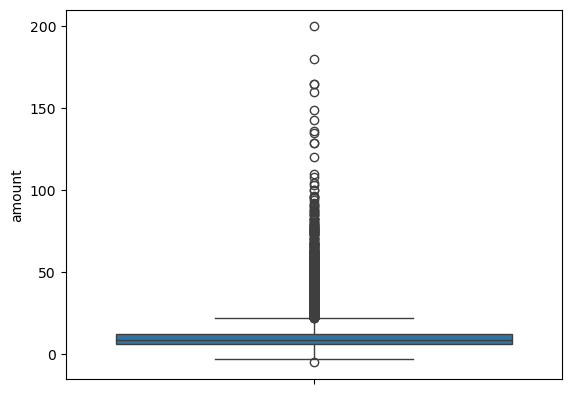

In [8]:
# checking the outliers
#using box plot to check the outliers
sns.boxplot(df['amount'])

#Displaying the plot
plt.show()


In [9]:
#Rectifying the outliers
Q1 = df['amount'].quantile(0.25)
Q3 = df['amount'].quantile(0.75)
IQR = Q3 - Q1

# Defining the bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# cleaning the dataset
df_no_outliers = df[(df['amount'] >= lower_bound) & (df['amount'] <= upper_bound)].copy()

#Checking the shape of the data
print("Original shape:", df.shape)
print("After removing outliers:", df_no_outliers.shape)


Original shape: (50000, 8)
After removing outliers: (45635, 8)


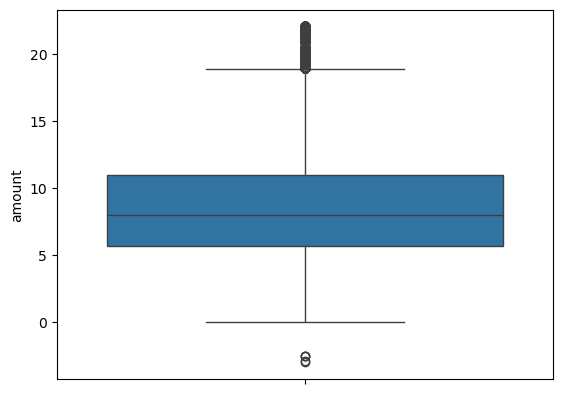

In [10]:
#After removing the outliers the data is shown using box plot
sns.boxplot(df_no_outliers['amount'])
#Displaying the plot
plt.show()


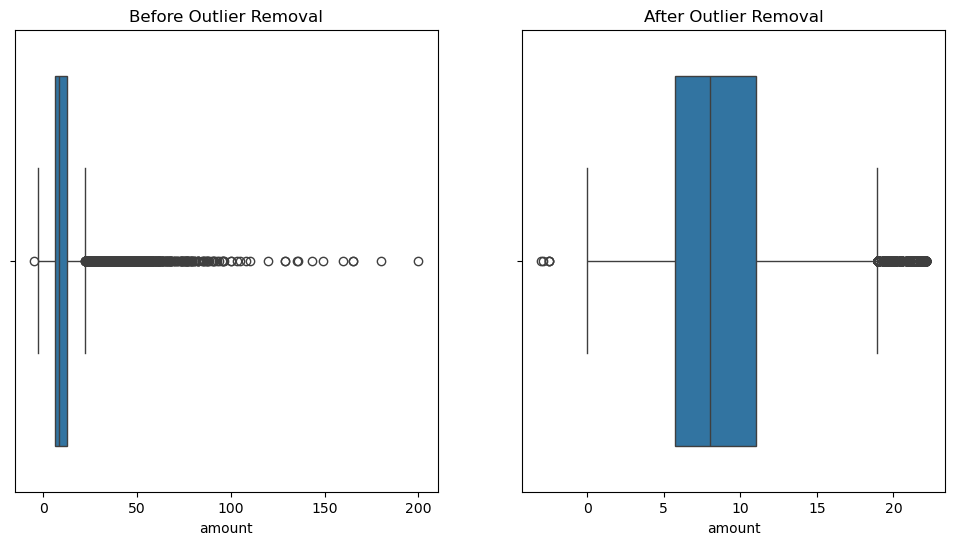

In [11]:
#showing both the before and after outliers  plots in th one frame
#Setting the figure size.
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

#Showing box plot for before outliers.
sns.boxplot(x=df['amount'],ax=axes[0])
#Adding Titles to the plot
axes[0].set_title("Before Outlier Removal")

#Showing box plot for after outliers
sns.boxplot(x=df_no_outliers['amount'], ax=axes[1])
axes[1].set_title("After Outlier Removal")

#Displaying the output
plt.show()


In [12]:
#Data type conversion.
#Date time converting
df_no_outliers["date_time_of_pickup"]=pd.to_datetime(df_no_outliers["date_time_of_pickup"])
print(df_no_outliers)

      unique_id       date_time_of_pickup  longitude_of_pickup  \
0       26:21.0 2009-06-15 17:26:21+00:00           -73.844311   
1       52:16.0 2010-01-05 16:52:16+00:00           -74.016048   
2       35:00.0 2011-08-18 00:35:00+00:00           -73.982738   
3       30:42.0 2012-04-21 04:30:42+00:00           -73.987130   
4       51:00.0 2010-03-09 07:51:00+00:00           -73.968095   
...         ...                       ...                  ...   
49995   25:15.0 2013-06-12 23:25:15+00:00           -73.999973   
49996   19:18.0 2015-06-22 17:19:18+00:00           -73.984756   
49997   53:00.0 2011-01-30 04:53:00+00:00           -74.002698   
49998   09:00.0 2012-11-06 07:09:00+00:00           -73.946062   
49999   13:14.0 2010-01-13 08:13:14+00:00           -73.932603   

       latitude_of_pickup  longitude_of_dropoff  latitude_of_dropoff  \
0               40.721319            -73.841610            40.712278   
1               40.711303            -73.979268            40.7

In [13]:
#Converting float values into integers
df_no_outliers['amount'] = df_no_outliers['amount'].astype(int)
df_no_outliers.head()

,unique_id,date_time_of_pickup,longitude_of_pickup,latitude_of_pickup,longitude_of_dropoff,latitude_of_dropoff,no_of_passenger,amount
0,26:21.0,2009-06-15 17:26:21+00:00,-73.844311,40.721319,-73.841610,40.712278,1,4
1,52:16.0,2010-01-05 16:52:16+00:00,-74.016048,40.711303,-73.979268,40.782004,1,16
2,35:00.0,2011-08-18 00:35:00+00:00,-73.982738,40.761270,-73.991242,40.750562,2,5
3,30:42.0,2012-04-21 04:30:42+00:00,-73.987130,40.733143,-73.991567,40.758092,1,7
4,51:00.0,2010-03-09 07:51:00+00:00,-73.968095,40.768008,-73.956655,40.783762,1,5


In [14]:
#Selecting the required features in X and target in y
features=['longitude_of_pickup','latitude_of_pickup', 'longitude_of_dropoff', 'latitude_of_dropoff',
       'no_of_passenger']

#Independent variable.
x = df[features]

#Target variable
y = df['amount']

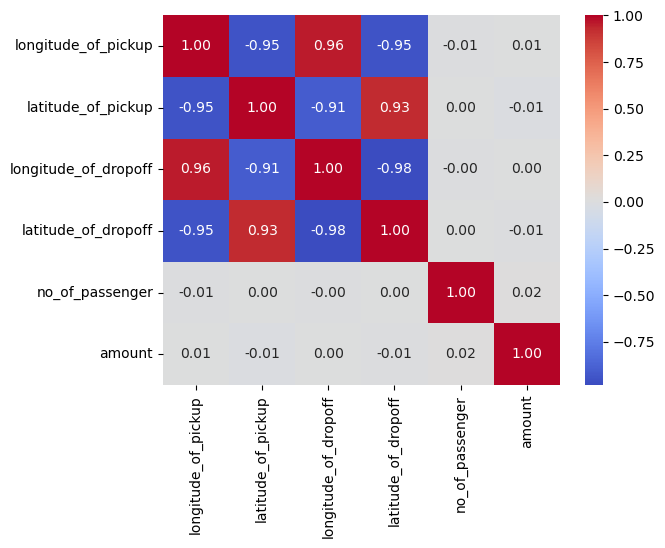

In [15]:
#Showing the correlation between independent and target.
import seaborn as sns
import matplotlib.pyplot as plt

# correlation
corr = df.corr(numeric_only=True)

# Plot heatmap
sns.heatmap(corr, annot=True, cmap="coolwarm",fmt=".2f")

#Displaying the plot
plt.show()


In [16]:
#Features scaling
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
x_scaled=scaler.fit_transform(x)
print(x_scaled)

[[-0.12839972  0.12651983 -0.1284649   0.13068477 -0.51803399]
 [-0.14492282  0.12491079 -0.14169175  0.14227741 -0.51803399]
 [-0.14171801  0.13293788 -0.14284227  0.13704986  0.25765179]
 ...
 [-0.14363839  0.12942901 -0.14350199  0.13853307 -0.51803399]
 [-0.13818935  0.13555596 -0.13921103  0.14189218  0.25765179]
 [-0.13689444  0.13334512 -0.13720795  0.13925164 -0.51803399]]


In [17]:
#Train_test_split
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x_scaled, y, test_size=0.2, random_state=42)

In [18]:
#Model Training
from sklearn.ensemble import RandomForestRegressor
rfr=RandomForestRegressor(n_estimators=200, max_depth=15, random_state=42, n_jobs=-1)
rfr.fit(x_train,y_train)

,n_estimators,200
,criterion,'squared_error'
,max_depth,15
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [19]:
#Model Prediction
y_pred=rfr.predict(x_test)
y_pred

array([ 7.98939087, 28.23618207,  8.01129721, ...,  8.03690225,
       33.02989984,  7.98341755], shape=(10000,))

In [20]:
#Evaluating r2-score,RMSE,MAE
from sklearn.metrics import r2_score,mean_squared_error, mean_absolute_error
print("R² Score:", r2_score(y_test, y_pred))
print("RMSE:", mean_squared_error(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))

R² Score: 0.6941147246066982
RMSE: 28.438433827494322
MAE: 2.9867073679183815


In [21]:
# Converting continuous fares into categories for calculating accuracy,confusion matrix,classification report
Y_test = (y_test > 20).astype(int)   # 1 = High fare, 0 = Low fare
Y_pred = (y_pred > 20).astype(int)

In [22]:
#Calculating Accuracy
from sklearn.metrics import accuracy_score
print("Accuracy:", accuracy_score(Y_test, Y_pred))


Accuracy: 0.9622


In [23]:
# Evaluating the Confusion Matrix 
#It shows how many predictions were correct vs.incorrect, broken down into categories: TP, TN, FP, FN.
#From sklearn we are importing confusion matrix,

from sklearn.metrics import confusion_matrix
cm=confusion_matrix(Y_test, Y_pred)
cm

array([[8861,  110],
       [ 268,  761]])

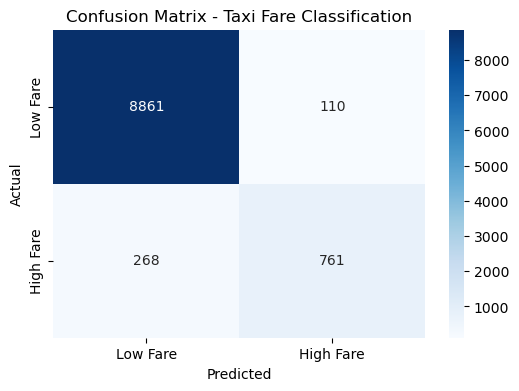

In [24]:
# Showing Confusion Matrix Heatmap - Visual of correct vs wrong predictions.
from sklearn.metrics import confusion_matrix

# Compute confusion matrix
cm = confusion_matrix(Y_test, Y_pred)

# Setting fig size
plt.figure(figsize=(6,4))

# Ploting heatmap
sns.heatmap(cm, annot=True, fmt='d', cmap="Blues", 
            xticklabels=["Low Fare","High Fare"], 
            yticklabels=["Low Fare","High Fare"])
#Adding the labels
plt.xlabel("Predicted")
plt.ylabel("Actual")

# Adding the title
plt.title("Confusion Matrix - Taxi Fare Classification")

#Display the plot
plt.show()


In [25]:
#Evaluating the classification report to show precision,recall,F1-score ,support.
#where precision shows Out of all predicted positives, how many were correct.
#Where Recall shows Out of all actual positives, how many were correctly predicted.
#Where F1-score shows the balance between precision and recall.
#Where Supportshows Number of actual occurrences of each class in the dataset.

#Importing the classification report library.
from sklearn.metrics import classification_report
print(classification_report(Y_test,Y_pred,target_names=["Low Fare","High Fare"]))

              precision    recall  f1-score   support

    Low Fare       0.97      0.99      0.98      8971
   High Fare       0.87      0.74      0.80      1029

    accuracy                           0.96     10000
   macro avg       0.92      0.86      0.89     10000
weighted avg       0.96      0.96      0.96     10000



In [26]:
#Cross validation score
#This evaluation metric values obtained from cross‑validation folds, showing how consistently the model performs across different subsets of the data.
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(rfr, x_scaled, y, cv=5)
print("Cross-validation scores:", cv_scores)



Cross-validation scores: [0.71927374 0.71833883 0.6755279  0.73195698 0.7092319 ]
